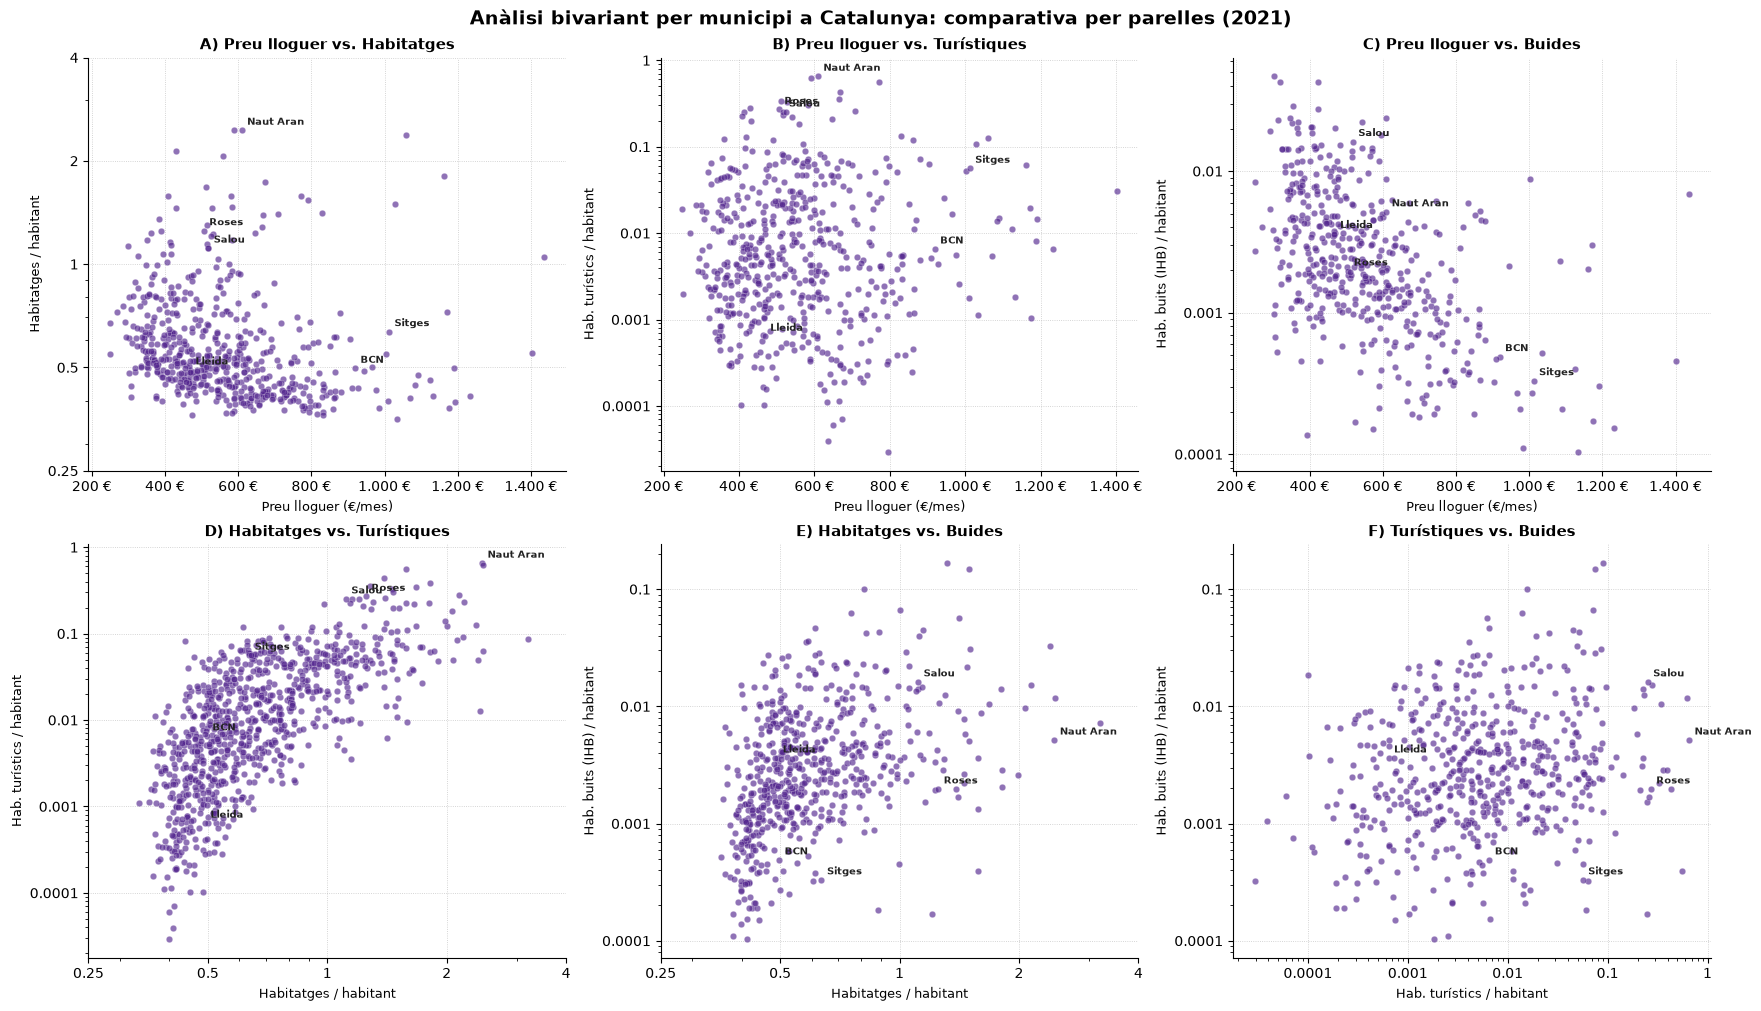

In [ ]:
# Exploració per parelles (6 subplots): sense valors 0 i amb escales logarítmiques pures (2021)

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

# 1. CAPA GEOGRÀFICA, POBLACIÓ I HABITATGES TOTALS (2021)
municipis = gpd.read_file("../Data/CatalunyaMapMunicipalities.json")  # Carregar capa geogràfica per municipis de Catalunya
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convertir el codi municipal a text de 6 dígits amb zeros a l'esquerra

ruta_pob = "../Data/BuildingsAvailable/poblacio_codis.xlsx"
df_pob = pd.read_excel(ruta_pob, sheet_name="Dades", skiprows=1, dtype={0: str})
df_pob = df_pob.rename(columns={df_pob.columns[0]: "Codi", df_pob.columns[1]: "Any"})
df_pob["Codi"] = df_pob["Codi"].ffill().str.strip().str.zfill(6)
df_pob = df_pob[df_pob["Codi"].str.match(r"^\d{6}$")].copy()
df_pob["Any"] = df_pob["Any"].astype(int)
df_pob["Poblacio"] = pd.to_numeric(df_pob["Total"], errors="coerce")
pob_2021 = df_pob[df_pob["Any"] == 2021][["Codi", "Poblacio"]]

ruta_hab = "../Data/BuildingsAvailable/habitatges2021.csv"
df_hab = pd.read_csv(ruta_hab, sep=";", skiprows=5, dtype={"Codi": str})
df_hab = df_hab.dropna(subset=["Codi"]).copy()
df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)
df_hab["Total"] = pd.to_numeric(df_hab["Total habitatges familiars"], errors="coerce")

# 2. DADES DE LLOGUER, HABITATGES TURÍSTICS I HABITATGES BUITS (2021)
# 2A. Preu mitjà del lloguer (RentPrice.csv -> 2021 anual)
ruta_lloguer = "../Data/RentPrice/RentPrice.csv"
df_lloguer = pd.read_csv(ruta_lloguer, sep=";", dtype=str)
df_lloguer = df_lloguer[
    (df_lloguer["Àmbit territorial"] == "Municipi")
    & (df_lloguer["Any"] == "2021")
    & (df_lloguer["Període"] == "gener-desembre")
].copy()
df_lloguer["Codi5"] = df_lloguer["Codi territorial"].str.strip().str.zfill(5)
df_lloguer["Lloguer"] = pd.to_numeric(
    df_lloguer["Renda"].str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
    errors="coerce",
)

# 2B. Habitatges d'ús turístic (TouristicRentals.csv)
ruta_tur = "../Data/TouristicRentals/TouristicRentals.csv"
df_tur = pd.read_csv(ruta_tur, dtype=str)
df_hut = df_tur[df_tur["Tipus establiment"] == "Habitatges d'ús turístic"].copy()
df_hut["Codi"] = df_hut["Codi Municipi (IDESCAT)"].str.strip().str.zfill(6)
tur_per_muni = df_hut.groupby("Codi").size().reset_index(name="Num_turistics")

# 2C. Habitatges buits (EmptyBuildings.csv -> IHB exercici 2021)
ruta_buits = "../Data/EmptyBuildings/EmptyBuildings.csv"
df_ihb = pd.read_csv(ruta_buits, dtype=str)
df_ihb_2021 = df_ihb[df_ihb["Any"] == "2021"].copy()
df_ihb_2021["Codi"] = df_ihb_2021["Codi"].str.strip().str.zfill(6)
df_ihb_2021["Habitatges"] = pd.to_numeric(df_ihb_2021["Habitatges"].str.replace(".", "", regex=False), errors="coerce")
buits_per_muni = df_ihb_2021.groupby("Codi")["Habitatges"].sum().reset_index(name="Num_buits")

# 3. CREUAR TOTES LES VARIABLES I NORMALITZAR PER HABITANT (SENSE OMPLIR AMB 0)
df_base = (
    df_hab[["Codi", "Total"]]
    .merge(pob_2021, on="Codi", how="inner")
    .merge(municipis[["CODIMUNI", "NOMMUNI"]], left_on="Codi", right_on="CODIMUNI", how="inner")
    .merge(tur_per_muni, on="Codi", how="left")
    .merge(buits_per_muni, on="Codi", how="left")
)
df_base = df_base.dropna(subset=["Total", "Poblacio"]).copy()
df_base = df_base[(df_base["Poblacio"] > 0) & (df_base["Total"] > 0)].copy()

# Calcular ràtios per habitant (els municipis sense registre queden com a NaN)
df_base["Hab_per_hab"] = df_base["Total"] / df_base["Poblacio"]
df_base["Tur_per_hab"] = df_base["Num_turistics"] / df_base["Poblacio"]
df_base["Buits_per_hab"] = df_base["Num_buits"] / df_base["Poblacio"]

# Afegir el preu del lloguer
df_base["Codi5"] = df_base["Codi"].str[:5]
df = df_base.merge(df_lloguer[["Codi5", "Lloguer"]], on="Codi5", how="left")

# 4. GENERAR ELS 6 SUBPLOTS EN UNA GRAELLA 2x3 (NOMÉS VALORS > 0)
fig, axes = plt.subplots(2, 3, figsize=(17.5, 10), layout="constrained")
axes = axes.flatten()

# Configuració de cada parella: (col_x, col_y, etiqueta_x, etiqueta_y, títol, escala_x, escala_y)
parelles = [
    ("Lloguer", "Hab_per_hab", "Preu lloguer (€/mes)", "Habitatges / habitant", "A) Preu lloguer vs. Habitatges", "linear", "log"),
    ("Lloguer", "Tur_per_hab", "Preu lloguer (€/mes)", "Hab. turístics / habitant", "B) Preu lloguer vs. Turístiques", "linear", "log"),
    ("Lloguer", "Buits_per_hab", "Preu lloguer (€/mes)", "Hab. buits (IHB) / habitant", "C) Preu lloguer vs. Buides", "linear", "log"),
    ("Hab_per_hab", "Tur_per_hab", "Habitatges / habitant", "Hab. turístics / habitant", "D) Habitatges vs. Turístiques", "log", "log"),
    ("Hab_per_hab", "Buits_per_hab", "Habitatges / habitant", "Hab. buits (IHB) / habitant", "E) Habitatges vs. Buides", "log", "log"),
    ("Tur_per_hab", "Buits_per_hab", "Hab. turístics / habitant", "Hab. buits (IHB) / habitant", "F) Turístiques vs. Buides", "log", "log"),
]

# Municipis clau per situar-se ràpidament a cada gràfic
municipis_ref = [
    (r"^Barcelona$", "BCN"),
    (r"^Salou$", "Salou"),
    (r"^Roses$", "Roses"),
    (r"^Naut Aran$", "Naut Aran"),
    (r"^Lleida$", "Lleida"),
    (r"^Sitges$", "Sitges"),
]

fmt_euros = ticker.FuncFormatter(lambda x, _: f"{int(x):,} €".replace(",", "."))
fmt_decimal = ticker.FuncFormatter(lambda x, _: f"{x:g}")

for ax, (col_x, col_y, lbl_x, lbl_y, titol, esc_x, esc_y) in zip(axes, parelles):
    # Eliminar files sense dada (NaN) o amb valor 0 en qualsevol dels dos eixos
    sub = df.dropna(subset=[col_x, col_y]).copy()
    sub = sub[(sub[col_x] > 0) & (sub[col_y] > 0)].copy()

    ax.scatter(
        sub[col_x],
        sub[col_y],
        color="#54278f",
        s=22,
        alpha=0.65,
        edgecolors="white",
        linewidth=0.25,
        zorder=3,
    )

    # Configurar escales de l'eix X
    if esc_x == "log":
        ax.set_xscale("log")
        if col_x == "Hab_per_hab":
            ax.set_xticks([0.25, 0.5, 1, 2, 4])
        ax.xaxis.set_major_formatter(fmt_decimal)
        ax.xaxis.set_minor_formatter(ticker.NullFormatter())
    else:
        ax.xaxis.set_major_formatter(fmt_euros)

    # Configurar escales de l'eix Y
    if esc_y == "log":
        ax.set_yscale("log")
        if col_y == "Hab_per_hab":
            ax.set_yticks([0.25, 0.5, 1, 2, 4])
        ax.yaxis.set_major_formatter(fmt_decimal)
        ax.yaxis.set_minor_formatter(ticker.NullFormatter())
    else:
        ax.yaxis.set_major_formatter(fmt_euros)

    # Etiquetar els municipis de referència
    for patro, nom_curt in municipis_ref:
        fila = sub[sub["NOMMUNI"].str.contains(patro, case=False, regex=True)]
        if not fila.empty:
            r = fila.iloc[0]
            ax.annotate(
                nom_curt,
                xy=(r[col_x], r[col_y]),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=7.2,
                fontweight="bold",
                color="#222222",
                zorder=4,
            )

    ax.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.7, zorder=1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlabel(lbl_x, fontsize=9.5)
    ax.set_ylabel(lbl_y, fontsize=9.5)
    ax.set_title(titol, fontweight="bold", fontsize=10.5)

fig.suptitle(
    "Anàlisi bivariant per municipi a Catalunya: comparativa per parelles (2021)",
    fontweight="bold",
    fontsize=13.5,
)

plt.show()